In [1]:
import tensorflow as tf

In [3]:
import numpy as np

SEED =42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [10]:
scaler = tf.constant(7)

scaler.ndim

0

In [13]:
vector = tf.constant([1,2,3])
vector.ndim

1

In [2]:
 import os
 os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2" #quieter logs
 import tensorflow as tf
 from tensorflow import keras
 import numpy as np
 import matplotlib.pyplot as plt
 from sklearn.datasets import make_moons
 from sklearn.model_selection import train_test_split

In [3]:
SEED =42
np.random.seed(SEED)


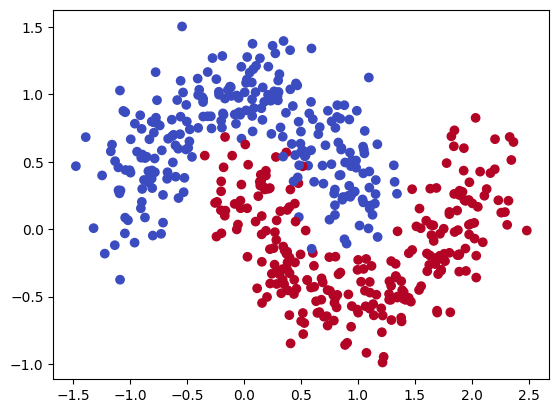

In [4]:
X,y = make_moons(n_samples=500,noise=0.2,random_state=SEED)
Y=y.reshape(500,1)

plt.scatter(X[:,0],X[:,1],c=Y,cmap='coolwarm')
plt.show()

In [5]:
X_temp,X_test,Y_temp,Y_test = train_test_split(X,Y,test_size=0.2,random_state=SEED)

In [6]:
X_train,X_val,Y_train,Y_val=train_test_split(X_temp,Y_temp,test_size=0.125,random_state=SEED)

In [7]:
X_train, X_val,X_test = (a.astype("float32") for a in (X_train,X_val,X_test))
Y_train,Y_val,Y_test = (a.astype("float32") for a in (Y_train,Y_val,Y_test))

print(X_train.shape , X_train.dtype)

(350, 2) float32


In [8]:
 #designing the NN
print(X_train[:5])

[[ 0.9975765  -0.30131006]
 [ 1.1046642  -0.5891254 ]
 [ 0.24138783  0.70733446]
 [ 0.8468365   0.8202573 ]
 [ 0.4486245  -0.24638017]]


In [9]:
#designing the NN

model = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(4,activation='sigmoid'),
    keras.layers.Dense(4,activation='sigmoid'),
    keras.layers.Dense(1,activation='sigmoid')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37 (148.00 B)

 Trainable params: 37 (148.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    loss = keras.losses.BinaryCrossentropy(),
    optimizer = keras.optimizers.Adam(learning_rate=0.01),
    metrics = ['accuracy']
)

In [12]:
#training the model

history = model.fit(
    X_train,Y_train,
    validation_data=(X_val,Y_val),
    batch_size=len(X_train),
    epochs=2000,
    verbose=0
)
print(f"final loss{history.history['loss'][-1]}")
print(f"final accuracy{history.history['accuracy'][-1]}")

final loss0.04581757262349129
final accuracy0.9828571677207947


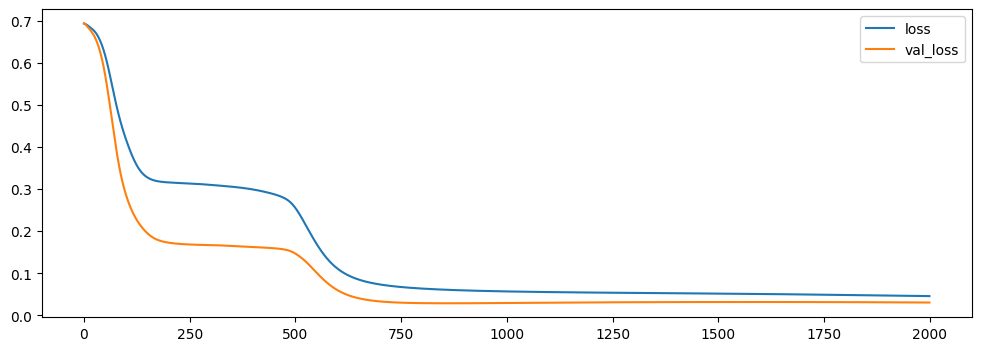

In [13]:
plt.figure(figsize=(12,4))
plt.plot(history.history['loss'],label='loss')
plt.plot(history.history['val_loss'],label='val_loss')
plt.legend()
plt.show()

In [14]:
#accuracy for each split
for name,xs,ys in ("Train",X_train,Y_train),("Val",X_val,Y_val),("Test",X_test,Y_test):
    print(f"{name} accuracy: {model.evaluate(xs,ys,verbose=0)[1]}")

Train accuracy: 0.9828571677207947
Val accuracy: 0.9800000190734863
Test accuracy: 0.9800000190734863


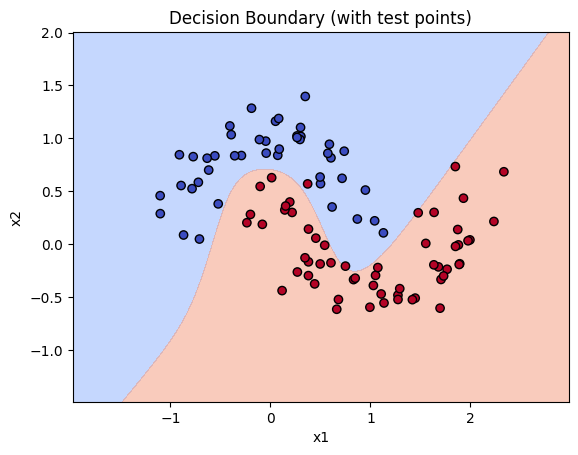

In [16]:
#draw the decision boundary
#visualize the decision boundary

# Create a grid of points covering the data
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

# Predict for each grid point
zz = model.predict(grid,verbose=0).reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], cmap='coolwarm', alpha=0.5)
# Plot test set points to show how well boundary generalizes
plt.scatter(X_test[:, 0], X_test[:, 1], c=Y_test.ravel(),
            cmap='coolwarm', edgecolor='k')
plt.title("Decision Boundary (with test points)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()
